# Auditoría de los modelos exportados de LinkShield AI

Verifica que las métricas sirvan como evidencia reproducible del proyecto. El notebook revisa los 14 modelos que cataloga la API, comprueba la partición del experimento híbrido y compara los errores del ensamble con su rama Random Forest entrenada para ese experimento.

Ejecuta **Run All** desde la carpeta `phishing-url-ai` o desde la raíz del repositorio. Si mueves el notebook, indica la raíz en `REPO_DIR` en la primera celda. Se requiere un kernel de Python con `numpy`, `pandas` y `matplotlib`.

La auditoría usa archivos locales en modo de lectura. Calcula huellas SHA-256 sin deserializar los modelos, no solicita predicciones ni abre enlaces del dataset. Para renovar resultados después de una exportación, vuelve a ejecutar el notebook.

In [1]:
from hashlib import sha256
from itertools import combinations
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

REPO_DIR = None  # Ejemplo: Path("/ruta/phishing-url-classifier")
cwd = Path.cwd()
location = Path(REPO_DIR).expanduser().resolve() if REPO_DIR else cwd
root = next(
    (p for p in (location, *location.parents)
     if (p / "phishing-url-api/models/model_registry.json").is_file()
     and (p / "phishing-url-ai").is_dir()),
    None,
)
if root is None:
    raise FileNotFoundError(
        "Abre el notebook desde el repositorio o ajusta REPO_DIR en esta celda."
    )

ai = root / "phishing-url-ai"
api_models = root / "phishing-url-api/models"
registry_file = api_models / "model_registry.json"
hybrid_file = ai / "models/hybrid/hybrid_registry.json"
metrics_file = ai / "models/hybrid/metricas_modelo_hibrido.csv"
split_file = ai / "models/sequential/split_indices.npz"

catalog = json.loads(registry_file.read_text(encoding="utf-8"))
hybrid = json.loads(hybrid_file.read_text(encoding="utf-8"))
hybrid_metrics = pd.read_csv(metrics_file).set_index("model_id")
models = {item["id"]: item for item in catalog["models"]}

if len(models) != len(catalog["models"]):
    raise ValueError("El registro contiene identificadores duplicados.")
if catalog["default_model_id"] not in models:
    raise ValueError("El modelo predeterminado no figura en el catálogo.")

print(f"Modelos registrados: {len(models)}")
print(f"Modelo predeterminado: {models[catalog['default_model_id']]['display_name']}")
print(f"Versión de esquema: {catalog['schema_version']}")

Modelos registrados: 14
Modelo predeterminado: LinkShield Hybrid Ensemble
Versión de esquema: 2


## Partición y soporte de la prueba

Se contrastan los índices guardados por el notebook 10 y reutilizados por el notebook 11. Una partición válida no repite índices dentro de cada conjunto, no comparte filas con otro conjunto y cubre el dataset usado en el experimento. La comprobación de índices no evalúa semejanza entre URLs o dominios.

In [2]:
partition_names = ("train", "validation", "calibration", "test")
partition_labels = ("Entrenamiento", "Validación", "Calibración", "Prueba")
with np.load(split_file, allow_pickle=False) as exported:
    partitions = {name: exported[name] for name in partition_names}

# Replicar la preparación de las etiquetas del notebook 11 sin mostrar URLs.
dataset = pd.read_csv(ai / hybrid["dataset"]["name"], usecols=["url", "status"])
labels = dataset.dropna(subset=["url", "status"])["status"].astype(int).to_numpy()
if not set(labels).issubset({0, 1}):
    raise ValueError("Se esperaban 0 para legítima y 1 para phishing.")

for name, indices in partitions.items():
    if indices.ndim != 1 or indices.dtype.kind not in "iu":
        raise ValueError(f"Índices inválidos en {name}.")
    if len(indices) != len(np.unique(indices)):
        raise ValueError(f"Índices repetidos en {name}.")
    if np.any((indices < 0) | (indices >= len(labels))):
        raise ValueError(f"Índices fuera del dataset en {name}.")
    if len(indices) != hybrid["dataset"][f"{name}_rows"]:
        raise ValueError(f"El tamaño de {name} difiere del manifiesto.")

for left, right in combinations(partition_names, 2):
    if np.intersect1d(partitions[left], partitions[right]).size:
        raise ValueError(f"Hay filas que aparecen en {left} y {right}.")

if sum(len(indices) for indices in partitions.values()) != len(labels):
    raise ValueError("Las particiones no cubren el dataset completo.")

rows = []
for name, label in zip(partition_names, partition_labels):
    selected = labels[partitions[name]]
    rows.append((label, len(selected), np.count_nonzero(selected == 0),
                 np.count_nonzero(selected == 1)))
display(pd.DataFrame(rows, columns=["Partición", "Filas", "Legítimas", "Phishing"])
        .set_index("Partición"))
print("Particiones completas, sin índices repetidos ni solapamientos.")

,Filas,Legítimas,Phishing
Partición,,,
Entrenamiento,6857,3428,3429
Validación,1143,572,571
Calibración,1143,572,571
Prueba,2286,1143,1143


Particiones completas, sin índices repetidos ni solapamientos.


## Métricas verificadas del catálogo

La clase positiva es phishing. Con cada matriz se vuelven a calcular accuracy, precisión, recall, F1 y las tasas de falsos positivos y negativos. El ROC-AUC se muestra como valor exportado porque la matriz de un umbral no contiene los puntajes por observación necesarios para reconstruirlo.

El catálogo reúne corridas con distintos datasets registrados, protocolos y umbrales. Esta tabla permite consultar resultados publicados. La comparación controlada entre el ensamble y la rama Random Forest se hace en la sección siguiente.

In [3]:
def rate(numerator, denominator):
    return numerator / denominator if denominator else np.nan


def matrix_metrics(tn, fp, fn, tp):
    return {
        "accuracy": rate(tn + tp, tn + fp + fn + tp),
        "precision": rate(tp, tp + fp),
        "recall": rate(tp, tp + fn),
        "f1": rate(2 * tp, 2 * tp + fp + fn),
        "fpr": rate(fp, tn + fp),
        "fnr": rate(fn, tp + fn),
    }


matrix_keys = ("tn", "fp", "fn", "tp")
families = {
    "machine_learning": "ML clásico",
    "deep_learning_tabular": "DL tabular",
    "deep_learning_sequential": "DL secuencial",
    "heuristic": "Heurístico",
    "hybrid": "Híbrido",
}
catalog_rows = []
mismatches = []

for model_id, model in models.items():
    matrix = model["confusion_matrix"]
    tn, fp, fn, tp = (matrix[key] for key in matrix_keys)
    if any(type(count) is not int or count < 0 for count in (tn, fp, fn, tp)):
        raise ValueError(f"Conteos de matriz inválidos en {model_id}.")

    calculated = matrix_metrics(tn, fp, fn, tp)
    if sum(matrix[key] for key in matrix_keys) != model["dataset"]["test_rows"]:
        mismatches.append(f"{model_id}: tamaño de prueba")
    for name in ("accuracy", "precision", "recall", "f1"):
        if not np.isclose(calculated[name], model["metrics"][name], atol=1e-8, rtol=0):
            mismatches.append(f"{model_id}: {name}")

    catalog_rows.append({
        "Modelo": model["display_name"],
        "Familia": families.get(model["family"], model["family"]),
        "Umbral": model["threshold"],
        "Accuracy": calculated["accuracy"],
        "Precisión": calculated["precision"],
        "Recall": calculated["recall"],
        "F1": calculated["f1"],
        "ROC-AUC (registro)": model["metrics"]["roc_auc"],
    })

catalog_frame = pd.DataFrame(catalog_rows).set_index("Modelo")
percentages = {name: "{:.2%}" for name in ("Umbral", "Accuracy", "Precisión", "Recall", "F1")}
display(catalog_frame.style.format({**percentages, "ROC-AUC (registro)": "{:.4f}"}))
if mismatches:
    raise ValueError("Diferencias en el registro:\n" + "\n".join(mismatches))
print(f"Las matrices reproducen las métricas de {len(models)} modelos.")

,Familia,Umbral,Accuracy,Precisión,Recall,F1,ROC-AUC (registro)
Modelo,,,,,,,
Regresión Logística,ML clásico,50.00%,91.43%,90.64%,92.39%,91.51%,0.9682
Árbol de Decisión,ML clásico,50.00%,91.73%,91.41%,92.13%,91.76%,0.9173
Random Forest Top 25,ML clásico,50.00%,94.88%,94.45%,95.36%,94.91%,0.9864
Gradient Boosting,ML clásico,50.00%,93.92%,93.28%,94.66%,93.96%,0.9830
K-Nearest Neighbors,ML clásico,50.00%,93.61%,93.46%,93.79%,93.62%,0.9638
Support Vector Machine,ML clásico,50.00%,93.74%,93.33%,94.23%,93.77%,0.9797
MLP Regularizada,DL tabular,50.00%,94.18%,95.01%,93.26%,94.13%,0.9826
MLP Compacta,DL tabular,50.00%,94.01%,93.44%,94.66%,94.05%,0.9820
MLP Residual,DL tabular,50.00%,93.53%,94.30%,92.65%,93.47%,0.9806


Las matrices reproducen las métricas de 14 modelos.


## Comparación entre el ensamble y su rama Random Forest

Ambas filas provienen de `metricas_modelo_hibrido.csv`, generada por el notebook 11. Las dos evaluaciones usan los índices de prueba de la primera sección. El Random Forest publicado como opción independiente en el catálogo tiene otra corrida y su matriz no se usa aquí.

In [4]:
hybrid_id = hybrid["id"]
comparison = hybrid_metrics.loc[[hybrid_id, "random_forest"]].copy()
comparison.index = ["Ensamble híbrido", "Rama Random Forest"]
test_labels = labels[partitions["test"]]
negative_count = np.count_nonzero(test_labels == 0)
positive_count = np.count_nonzero(test_labels == 1)

for name, row in comparison.iterrows():
    if (row.tn + row.fp, row.fn + row.tp) != (negative_count, positive_count):
        raise ValueError(f"La matriz de {name} no coincide con el soporte de prueba.")

ensemble = comparison.iloc[0]
reference = comparison.iloc[1]
derived = pd.DataFrame(
    [matrix_metrics(*(row[key] for key in matrix_keys)) for _, row in comparison.iterrows()],
    index=comparison.index,
)
summary = comparison[list(matrix_keys)].rename(
    columns=dict(zip(matrix_keys, ("VN", "FP", "FN", "VP")))
).astype(int).join(derived[["f1", "fpr", "fnr"]].rename(
    columns={"f1": "F1", "fpr": "Tasa FP", "fnr": "Tasa FN"}
))
display(summary.style.format({"F1": "{:.2%}", "Tasa FP": "{:.2%}", "Tasa FN": "{:.2%}"}))

error_delta = (ensemble[["fp", "fn"]] - reference[["fp", "fn"]]).astype(int)
f1_delta = (derived.iloc[0]["f1"] - derived.iloc[1]["f1"]) * 100
print(f"Ensamble menos Random Forest: {error_delta.fp:+d} FP, {error_delta.fn:+d} FN.")
print(f"Variación de F1: {f1_delta:+.3f} puntos porcentuales.")

,VN,FP,FN,VP,F1,Tasa FP,Tasa FN
Ensamble híbrido,1089,54,60,1083,95.00%,4.72%,5.25%
Rama Random Forest,1076,67,50,1093,94.92%,5.86%,4.37%


Ensamble menos Random Forest: -13 FP, +10 FN.
Variación de F1: +0.080 puntos porcentuales.


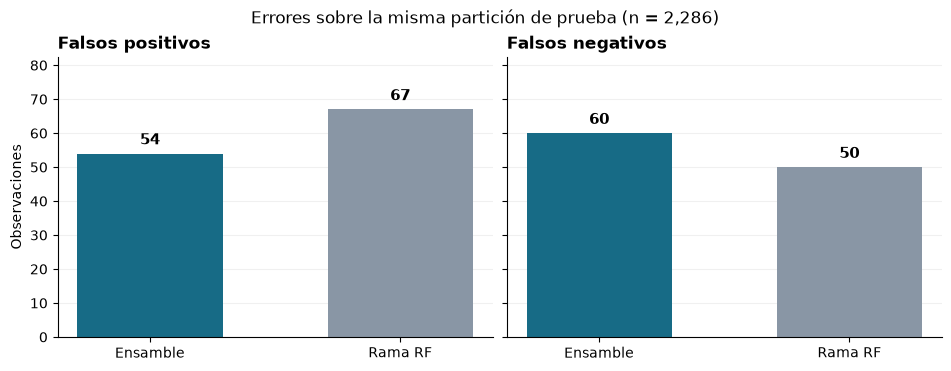

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(9.4, 3.6), layout="constrained", sharey=True)
colors = ("#176b86", "#8996a5")
for ax, column, title in zip(axes, ("FP", "FN"), ("Falsos positivos", "Falsos negativos")):
    values = summary[column].tolist()
    bars = ax.bar(["Ensamble", "Rama RF"], values, color=colors, width=0.58)
    ax.bar_label(bars, padding=4, fontsize=11, fontweight="bold")
    ax.set_title(title, loc="left", fontsize=12, fontweight="bold")
    ax.set_ylim(0, max(summary["FP"].max(), summary["FN"].max()) * 1.23)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.18)
    ax.set_axisbelow(True)
axes[0].set_ylabel("Observaciones")
fig.suptitle(f"Errores sobre la misma partición de prueba (n = {len(test_labels):,})", x=0.51)
plt.show()

Un delta negativo en FP indica menos falsas alarmas del ensamble. Un delta positivo en FN indica más casos de phishing que pasan sin alerta. F1 combina precisión y recall mediante su media armónica. El balance operativo depende del costo de cada tipo de error. La diferencia es descriptiva y no implica significancia estadística. Una prueba pareada requeriría las predicciones de ambos modelos para cada observación.

## Integridad de los archivos que usa la API

Se contrastan el manifiesto y la tabla híbrida en ambos módulos. También se verifican los prefijos de SHA-256 cuando forman parte de los registros. La huella prueba correspondencia con los metadatos exportados y permite detectar diferencias de archivo. La evaluación predictiva sigue sustentada por los experimentos y sus matrices.

In [6]:
def digest(path):
    with path.open("rb") as source:
        checksum = sha256()
        for chunk in iter(lambda: source.read(1024 * 1024), b""):
            checksum.update(chunk)
    return checksum.hexdigest()


checks = []


def check_artifact(name, relative_path, prefix=None):
    path = (api_models / relative_path).resolve()
    if not path.is_relative_to(api_models):
        raise ValueError(f"Ruta fuera del directorio de modelos: {relative_path}")
    actual = digest(path) if path.is_file() else ""
    matches = bool(actual) and (prefix is None or actual.startswith(prefix))
    checks.append((name, relative_path, prefix or "Existencia", actual[:12], matches))


for model_id, model in models.items():
    if model.get("artifact"):
        check_artifact(model_id, model["artifact"], model.get("artifact_id"))

ensemble_manifest = models[hybrid_id]
for role, relative in ensemble_manifest["artifacts"].items():
    expected = hybrid["artifact_ids"].get(role) or models.get(role, {}).get("artifact_id")
    check_artifact(f"{hybrid_id}/{role}", relative, expected)

for name in ("hybrid_registry.json", "metricas_modelo_hibrido.csv"):
    local_file = hybrid_file.parent / name
    check_artifact(f"Copia de {name}", f"hybrid/{name}", digest(local_file))

validation = pd.DataFrame(checks, columns=[
    "Registro", "Ruta relativa a models", "Huella esperada", "Huella encontrada", "Conforme",
])
display(validation[["Registro", "Ruta relativa a models", "Huella encontrada", "Conforme"]]
        .set_index("Registro"))

ensemble_csv = hybrid_metrics.loc[hybrid_id]
for source in (hybrid, ensemble_manifest):
    for metric, value in source["metrics"].items():
        if not np.isclose(ensemble_csv[metric], value, atol=1e-8, rtol=0):
            raise ValueError(f"No coincide la métrica híbrida {metric}.")
    if any(ensemble_csv[k] != source["confusion_matrix"][k] for k in matrix_keys):
        raise ValueError("La matriz del ensamble difiere de su tabla exportada.")

if not validation["Conforme"].all():
    raise ValueError("Revisa los archivos con resultado no conforme en la tabla.")
print(f"{len(validation)} referencias de archivo verificadas.")
print("El CSV y los dos manifiestos coinciden en las métricas y la matriz del ensamble.")

,Ruta relativa a models,Huella encontrada,Conforme
Registro,,,
logistic_regression,ml/registry/logistic_regression.pkl,1664feb4d381,True
decision_tree,ml/registry/decision_tree.pkl,a7273124d4e3,True
random_forest,ml/registry/random_forest.pkl,f14dc29db595,True
gradient_boosting,ml/registry/gradient_boosting.pkl,1605e88e9bb3,True
knn,ml/registry/knn.pkl,e346ffc6a492,True
svm,ml/registry/svm.pkl,5908b3a23df8,True
mlp_regularized,deep_learning/mlp_regularized.keras,3335195cd634,True
mlp_compact,deep_learning/mlp_compact.keras,684b28878443,True
mlp_residual,deep_learning/mlp_residual.keras,197cefa2560f,True


19 referencias de archivo verificadas.
El CSV y los dos manifiestos coinciden en las métricas y la matriz del ensamble.


**Fuentes locales.** `phishing-url-api/models/model_registry.json`; `phishing-url-ai/models/sequential/split_indices.npz`; los registros de `phishing-url-ai/models/hybrid`; y `11_modelo_hibrido_ml_dl_heuristicas.ipynb` para el protocolo del experimento. Si el registro, las matrices o el dataset cambian, usa los resultados de la ejecución actual como referencia.